# Cuaderno de Limpieza Estadística y Flujo a Capas Plata y Oro (Entrega E1)

**Proyecto:** Observatorio de Datos - Puestos Escolares (Colima, México)  
**Asignatura:** Ingeniería de Datos (ATD-2602) | 7mo Semestre, Ago-Dic 2026  
**Estudiante:** Yair Alejandro Molina Díaz (No. Control: 23460519)  
**Institución:** Tecnológico Nacional de México — Instituto Tecnológico de Colima  

---

### Contexto de Negocio y Vinculación con la Entrevista de Campo
En la Entrega E0 se identificó a través de una entrevista presencial a una comerciante escolar en Colima que:
1. Su demanda opera bajo una **estacionalidad dual**: calendario escolar (SEP) y temperatura ambiente (alta venta de jugos preparados congelados y nieve en verano).
2. Adquiere sus insumos por cajas en tiendas de mayoreo (*Sam's Club*) de forma puramente reactiva cuando se agota el inventario.
3. Requiere anticipar choques inflacionarios en sus insumos clave (azúcar, refrescos, concentrados, botanas y desechables).

**Objetivo de este Cuaderno:**  
Automatizar la ingesta, limpieza estadística, validación estricta con Pandera y segregación a cuarentena para alimentar las capas **Plata** y **Oro**, garantizando que ningún registro se pierda en silencio (reconciliación 100% auditable).


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as display

# Asegurar path al proyecto
BASE_DIR = Path.cwd().parent.parent if Path.cwd().name == "E1" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.pipeline.integracion import integrar_datos_bronce
from src.pipeline.calidad import PuertaCalidad
from src.pipeline.limpieza import diagnosticar_faltantes, experimento_imputacion, detectar_atipicos
from src.pipeline.transformacion import transformar_y_normalizar
from src.pipeline.reduccion import construir_capa_oro

print("Módulos del pipeline importados exitosamente desde src.pipeline.")


Módulos del pipeline importados exitosamente desde src.pipeline.


---
## Fase 1: Integración de Fuentes Heterogéneas y Resolución de Duplicados

### Reglas de Negocio Implementadas:
1. **Estandarización de Esquemas:** INEGI disemina fechas en formato `YYYY/MM` y Banxico en `DD/MM/YYYY`. Se homologan todas al primer día del mes ISO (`YYYY-MM-01`), excepto el tipo de cambio diario FIX (`SF43718`), que conserva el día (`YYYY-MM-DD`).
2. **Manejo de Textos No Numéricos:** Se detectan textos literales como `"N/E"` (No Existente) en Banxico `SP74625` (periodo 1969-1981, previo a la creación del subíndice subyacente). Estos registros se aíslan en cuarentena con causa auditable.
3. **Deduplicación:** Se procesan 12 capturas crudas históricas. Cuando existen registros repetidos para la misma serie y fecha, la captura más reciente gana; las capturas anteriores se trasladan a cuarentena como `"duplicado_captura_anterior"`.
4. **Agregación del Tipo de Cambio:** Se agregan las cotizaciones diarias hábiles de `SF43718` a nivel mensual bajo dos criterios:
   - `promedio_mensual`: Presión cambiaria media del mes.
   - `cierre_mensual`: Paridad del último día hábil cotizado.


In [2]:
df_plata_raw, df_cuarentena_f1, df_tc_mensual = integrar_datos_bronce(
    bronze_dir=BASE_DIR / "datos" / "bronce",
    plata_dir=BASE_DIR / "datos" / "plata",
    cuarentena_dir=BASE_DIR / "datos" / "cuarentena"
)

print(f"Total registros en Plata (Formato Largo): {len(df_plata_raw):,}")
print(f"Total registros en Cuarentena (Fase 1):   {len(df_cuarentena_f1):,}")
df_plata_raw.head()


2026-11-12 10:26:53,452 [INFO] Leyendo 12 archivos crudos en C:\Users\molin\Documents\7 SEMESTRE\ING Datos\Programas ING DATOS\Trusted Data Lab\datos\bronce...


2026-11-12 10:26:54,030 [INFO] Total de registros crudos leídos: 69249


2026-11-12 10:26:54,314 [INFO] Registros descartados por serie no activa o N/E: 4584 (N/E count: 936)


2026-11-12 10:26:54,721 [INFO] CONCILIACIÓN FASE 1 EXITOSA: 69249 (Entrada) == 11635 (Plata) + 57614 (Cuarentena)



INVENTARIO DE INTEGRACIÓN - FASE 1
Total registros brutos procesados: 69,249
Total registros aceptados en Plata:  11,635
Total registros en Cuarentena F1:   57,614
----------------------------------------------------------------------
Registros aceptados en Plata por Serie:
  [910392] Índice general                :    693 obs | 1969-01-01 a 2026-09-01
  [910394] Mercancías                    :    537 obs | 1982-01-01 a 2026-09-01
  [910395] Servicios                     :    537 obs | 1982-01-01 a 2026-09-01
  [910397] Agropecuarios                 :    537 obs | 1982-01-01 a 2026-09-01
  [SF43718] Tipo de cambio FIX            :  8,794 obs | 1991-11-12 a 2026-11-06
  [SP74625] Subíndice subyacente del INPC :    537 obs | 1982-01-01 a 2026-09-01
----------------------------------------------------------------------
Registros en Cuarentena por Regla:
  duplicado_captura_anterior      : 53,030 registros
  serie_no_seleccionada           :  3,648 registros
  valor_no_numerico_ne        

,fecha,cve_serie,nombre_literal,unidad_literal,fuente,valor,fecha_captura_utc,archivo_origen
0,1969-01-01,910392,Índice general,Índice base 2018=100,INEGI,0.011595,2026-11-09T01:34:25.313920+00:00,inegi_inpc_raw_20261109_013425.json
1,1969-02-01,910392,Índice general,Índice base 2018=100,INEGI,0.011636,2026-11-09T01:34:25.313920+00:00,inegi_inpc_raw_20261109_013425.json
2,1969-03-01,910392,Índice general,Índice base 2018=100,INEGI,0.011648,2026-11-09T01:34:25.313920+00:00,inegi_inpc_raw_20261109_013425.json
3,1969-04-01,910392,Índice general,Índice base 2018=100,INEGI,0.011680,2026-11-09T01:34:25.313920+00:00,inegi_inpc_raw_20261109_013425.json
4,1969-05-01,910392,Índice general,Índice base 2018=100,INEGI,0.011680,2026-11-09T01:34:25.313920+00:00,inegi_inpc_raw_20261109_013425.json


---
## Fase 2: Diagnóstico de Valores Faltantes y Experimento de Simulación

### Diagnóstico Honesto sobre Datos Reales:
En las series activas oficiales del INPC (actualización 2024 de INEGI) y en Banxico SIE, **no existen meses faltantes reales** en su periodo de vigencia activa (1982-2026 para subíndices; 1969-2026 para General).  
*Los 156 registros `"N/E"` de Banxico `SP74625` (1969-1981) corresponden a un mecanismo **MNAR (Missing Not At Random)** institucional: el Banco de México comenzó a calcular el subíndice subyacente a partir de 1982.*

### Experimento de Sensibilidad (SIMULACIÓN ETIQUETADA):
Dado que los datos reales no tienen ausencias, se ejecuta un experimento controlado sobre una copia de la serie *Mercancías* (`910394`), enmascarando artificialmente el **5%** y **10%** de las observaciones. Se comparan tres técnicas de imputación:
1. **Interpolación Lineal**
2. **Media Estacional del Mes** (agrupada por mes histórico)
3. **Spline Cúbico**


,cve_serie,nombre_literal,n_observaciones,nulos_detectados,meses_faltantes_calendario,mecanismo_ausencia
0,910392,Índice general,693,0,0,N/A (Serie completa 100%)
1,910394,Mercancías,537,0,0,N/A (Serie completa 100%)
2,910395,Servicios,537,0,0,N/A (Serie completa 100%)
3,910397,Agropecuarios,537,0,0,N/A (Serie completa 100%)
4,SF43718,Tipo de cambio FIX,8794,0,0,N/A (Serie completa 100%)
5,SP74625,Subíndice subyacente del INPC,537,0,0,N/A (Serie completa 100%)


2026-11-12 10:26:56,087 [INFO] Iniciando experimento de sensibilidad de imputación sobre serie 910394...


2026-11-12 10:26:57,217 [INFO] Gráfica de simulación guardada en: docs\E1\figuras\simulacion_imputacion.png


MÉTRICAS COMPARATIVAS DE IMPUTACIÓN (SIMULACIÓN):


,tasa_enmascaramiento,metodo,rmse,mae,k_imputados
0,5%,Interpolación Lineal,0.106776,0.074712,26
1,5%,Media Estacional del Mes,49.938065,43.522436,26
2,5%,Spline Cúbico,1.302616,1.065929,26
3,10%,Interpolación Lineal,0.087593,0.054401,53
4,10%,Media Estacional del Mes,41.721675,35.580398,53
5,10%,Spline Cúbico,1.180731,0.931881,53


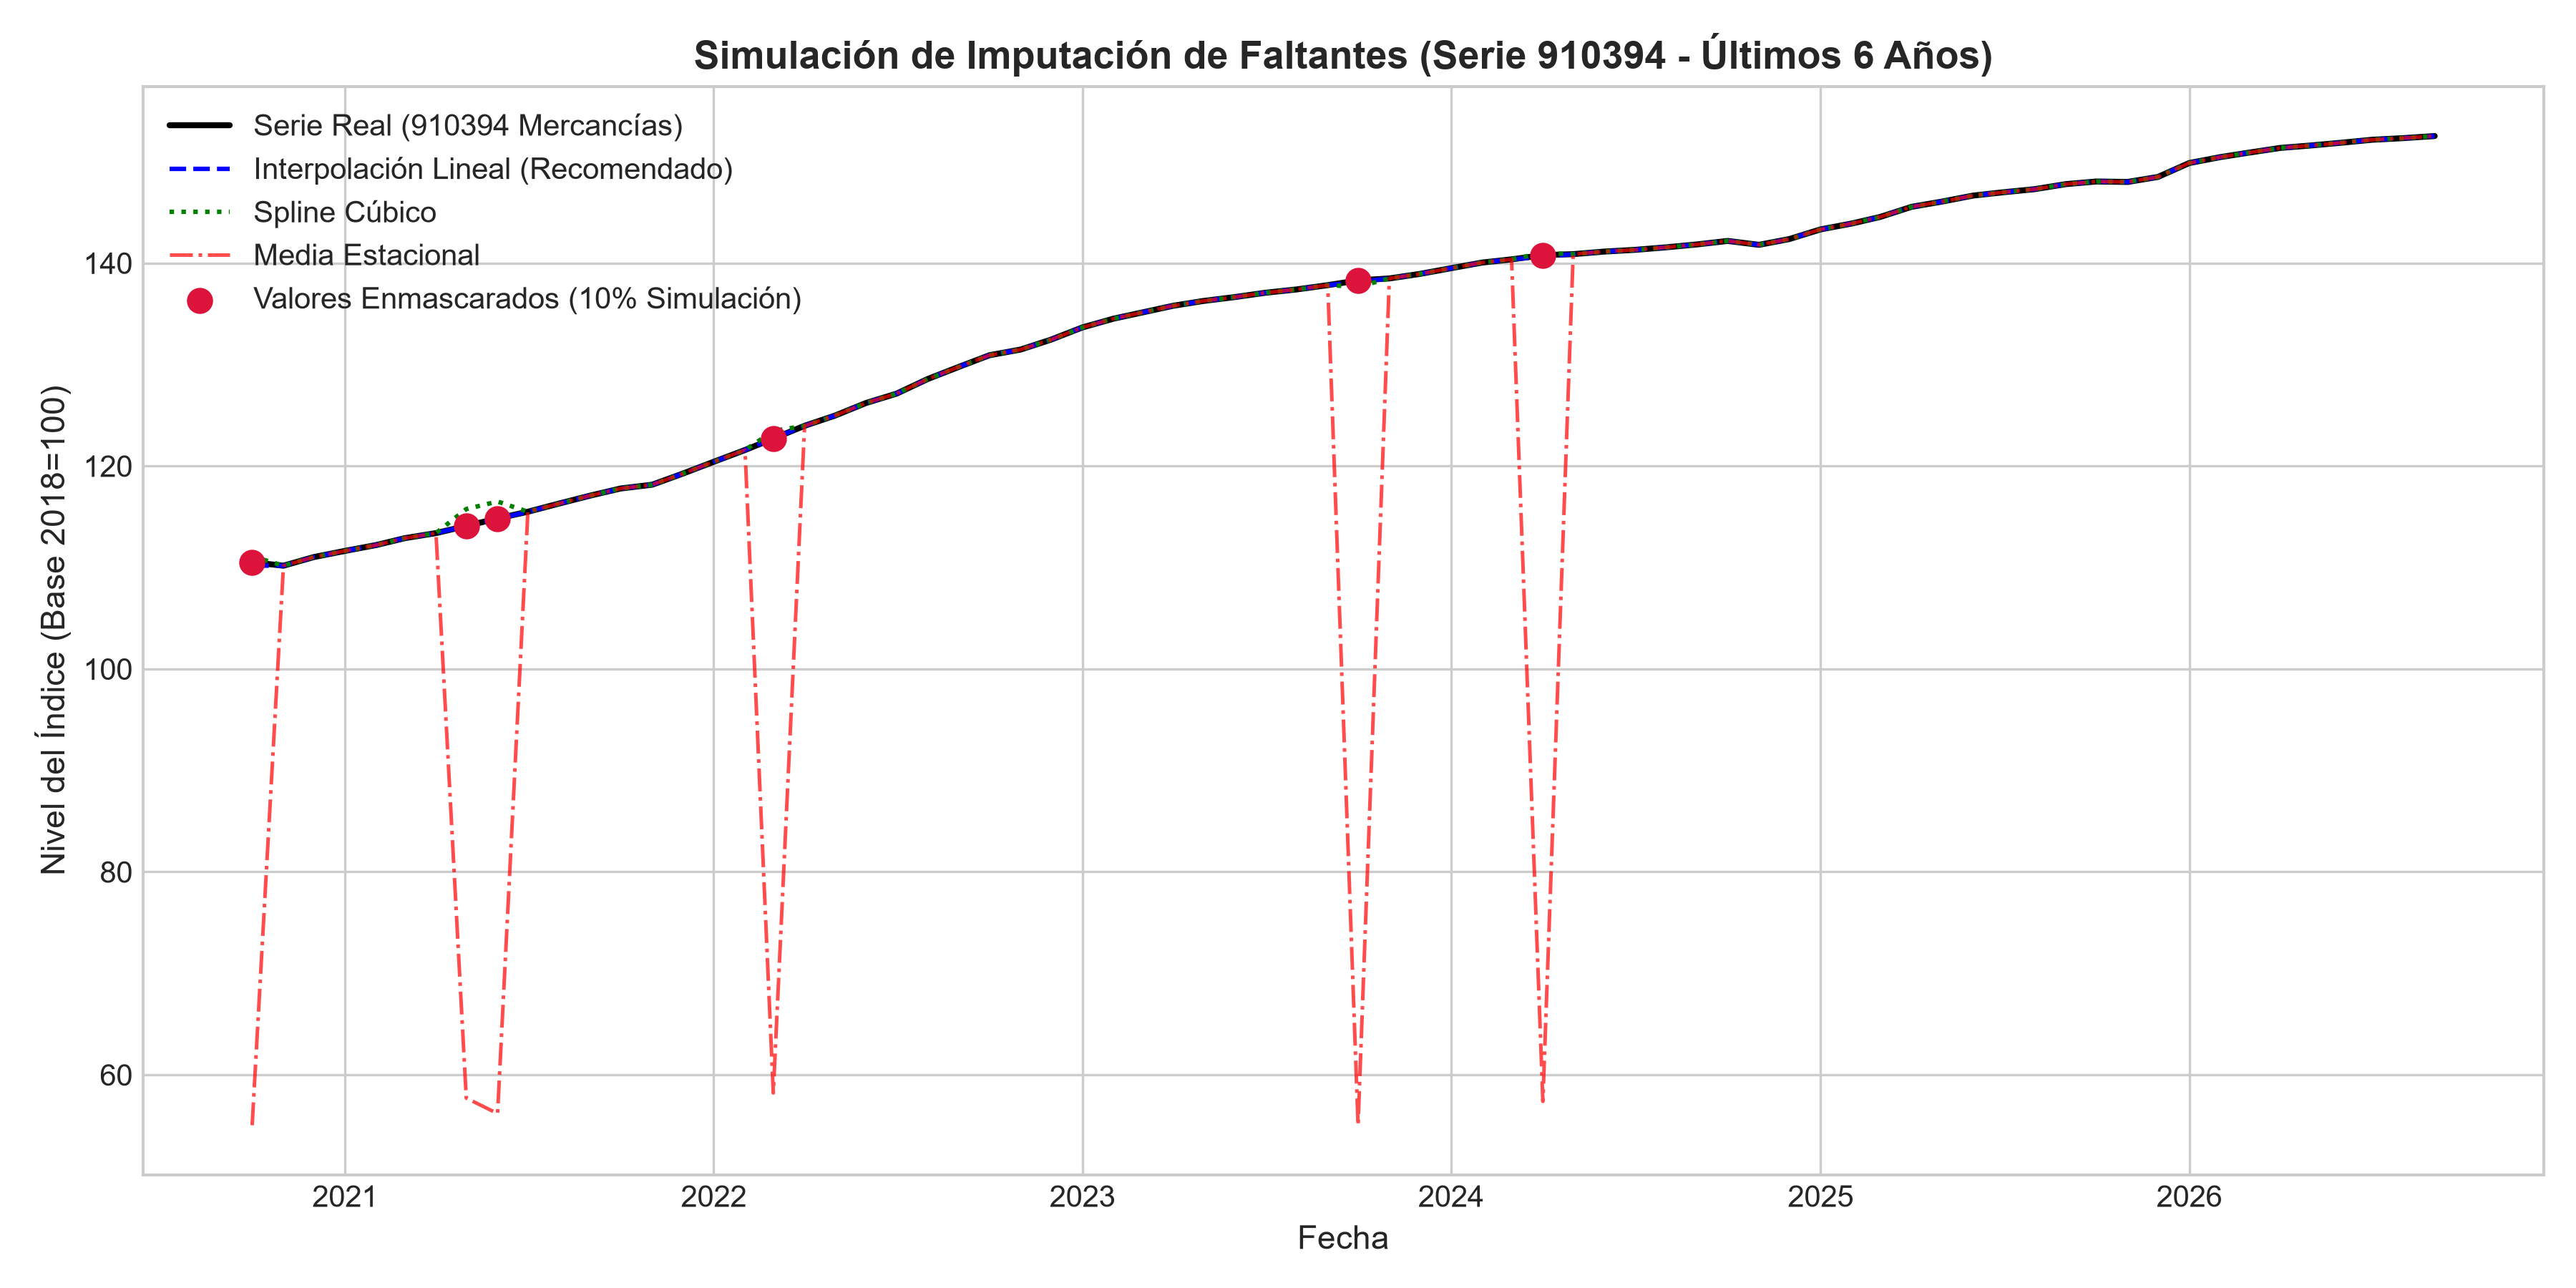

In [3]:
df_diag_faltantes = diagnosticar_faltantes(df_plata_raw)
display.display(df_diag_faltantes[["cve_serie", "nombre_literal", "n_observaciones", "nulos_detectados", "meses_faltantes_calendario", "mecanismo_ausencia"]])

# Ejecución del experimento de simulación
df_sim_res, _ = experimento_imputacion(df_plata_raw, serie_objetivo="910394")
print("MÉTRICAS COMPARATIVAS DE IMPUTACIÓN (SIMULACIÓN):")
display.display(df_sim_res)

# Mostrar la figura generada
display.display(display.Image(filename=str(BASE_DIR / "docs" / "E1" / "figuras" / "simulacion_imputacion.png")))


---
## Fase 3: Tratamiento de Atípicos y Ruido Estadístico

### Justificación Teórica: ¿Por qué NO aplicar IQR sobre niveles de precios?
Los índices de precios al consumidor ($I_t$) son series no estacionarias con tendencia estocástica y determinista creciente ($I(1)$) y quiebres estructurales severos (e.g. hiperinflación de los años 80 en México). Aplicar un filtro de Tukey (IQR) sobre los niveles clasificaría erróneamente todos los valores recientes o antiguos como "atípicos".

Por tanto, el análisis de atípicos se aplica rigurosamente sobre la **variación porcentual mensual estacionaria**:
$$\Delta\%_t = \left(\frac{I_t - I_{t-1}}{I_{t-1}}\right) \times 100$$

### Métodos Aplicados:
1. **Tukey IQR:** $[Q_1 - 1.5\cdot\text{IQR}, Q_3 + 1.5\cdot\text{IQR}]$
2. **Z-score Robusto con Mediana y MAD:** $|Z_{\text{MAD}}| > 3.0$, donde $Z_{\text{MAD}} = 0.6745 \cdot \frac{x - \text{mediana}}{\text{MAD}}$
3. **Isolation Forest:** Algoritmo no supervisado de árboles de aislamiento ($c=0.03$).

**Decisión Técnica Justificada:**  
Los valores extremos detectados (e.g. hiperinflación de 1987-1988 con inflación mensual de 15%, crisis de 1995 con 8%, y COVID-19 en 2020) **se conservan íntegros**. Son choques macroeconómicos reales; eliminarlos sesgaría el modelo.


2026-11-12 10:26:57,291 [INFO] Iniciando detección de atípicos sobre variaciones mensuales porcentuales...


2026-11-12 10:27:03,165 [INFO] Figuras generadas exitosamente en docs\E1\figuras


RESUMEN DE ATÍPICOS DETECTADOS POR MÉTODO:
[910392] Índice general                 | IQR: 86 | ZMAD: 100 | IForest: 21
[910394] Mercancías                     | IQR: 85 | ZMAD: 109 | IForest: 17
[910395] Servicios                      | IQR: 60 | ZMAD: 129 | IForest: 17
[910397] Agropecuarios                  | IQR: 23 | ZMAD: 22 | IForest: 17
[SF43718] Tipo de cambio FIX             | IQR: 555 | ZMAD: 420 | IForest: 264
[SP74625] Subíndice subyacente del INPC  | IQR: 78 | ZMAD: 121 | IForest: 17


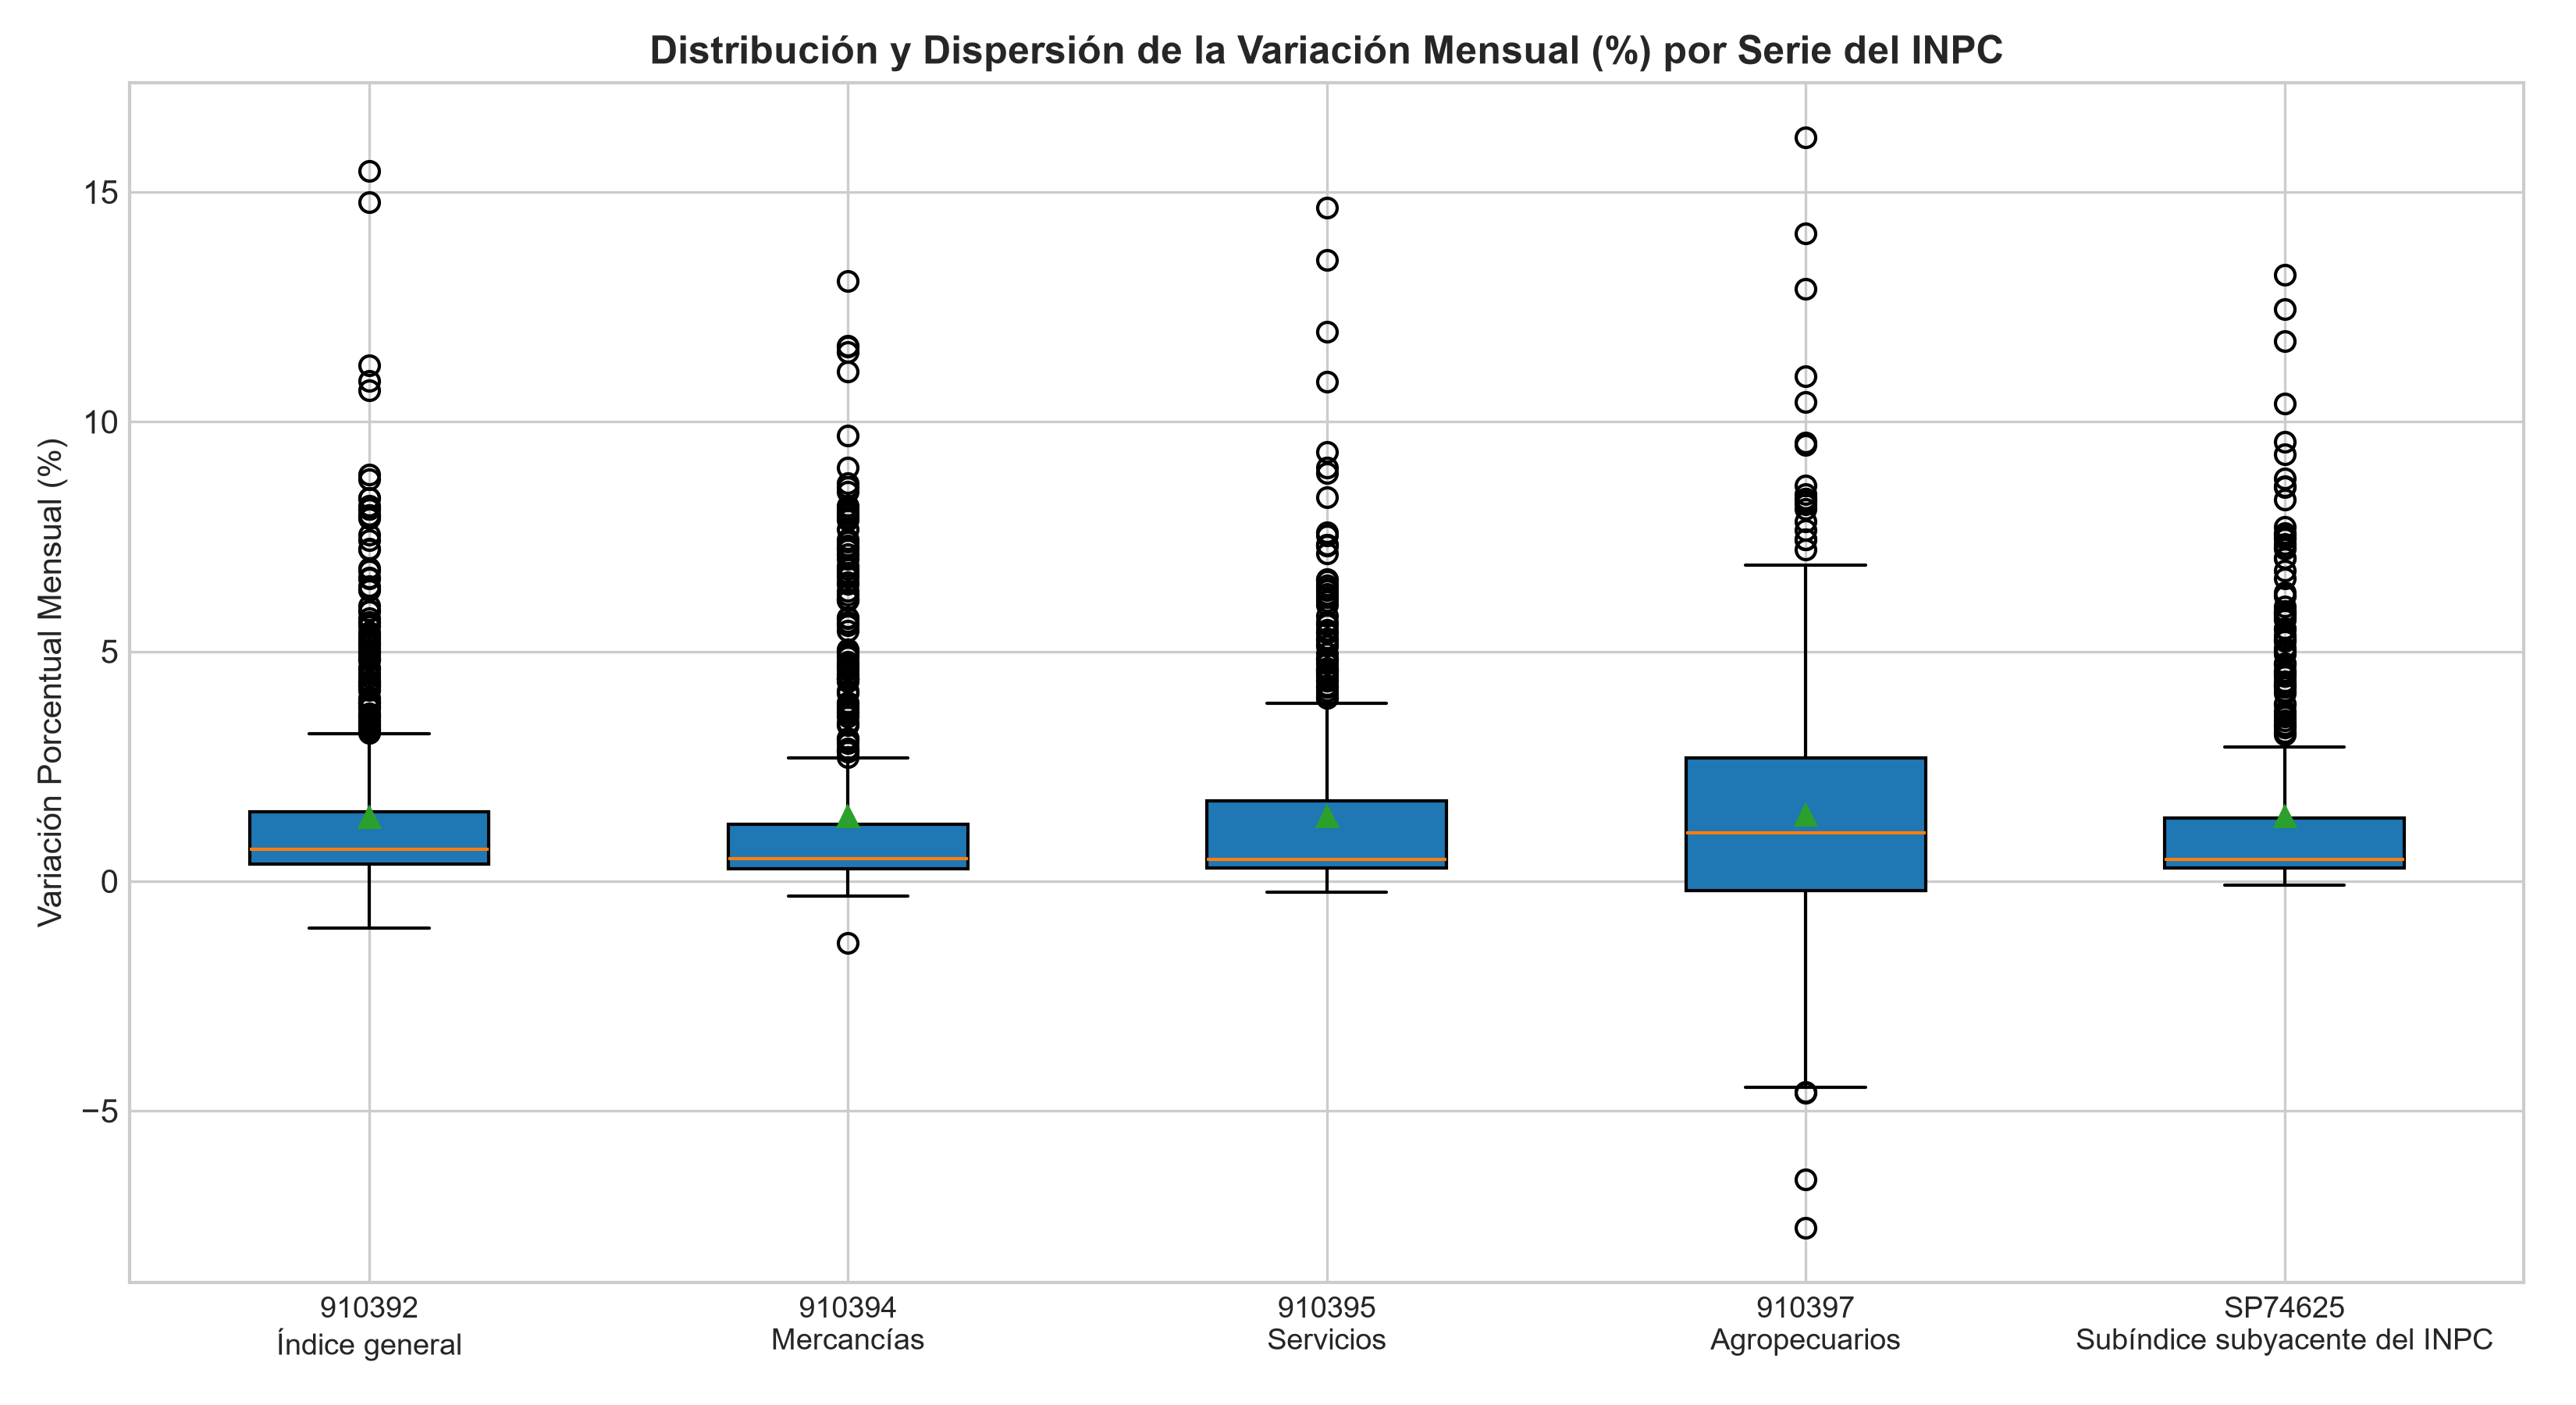

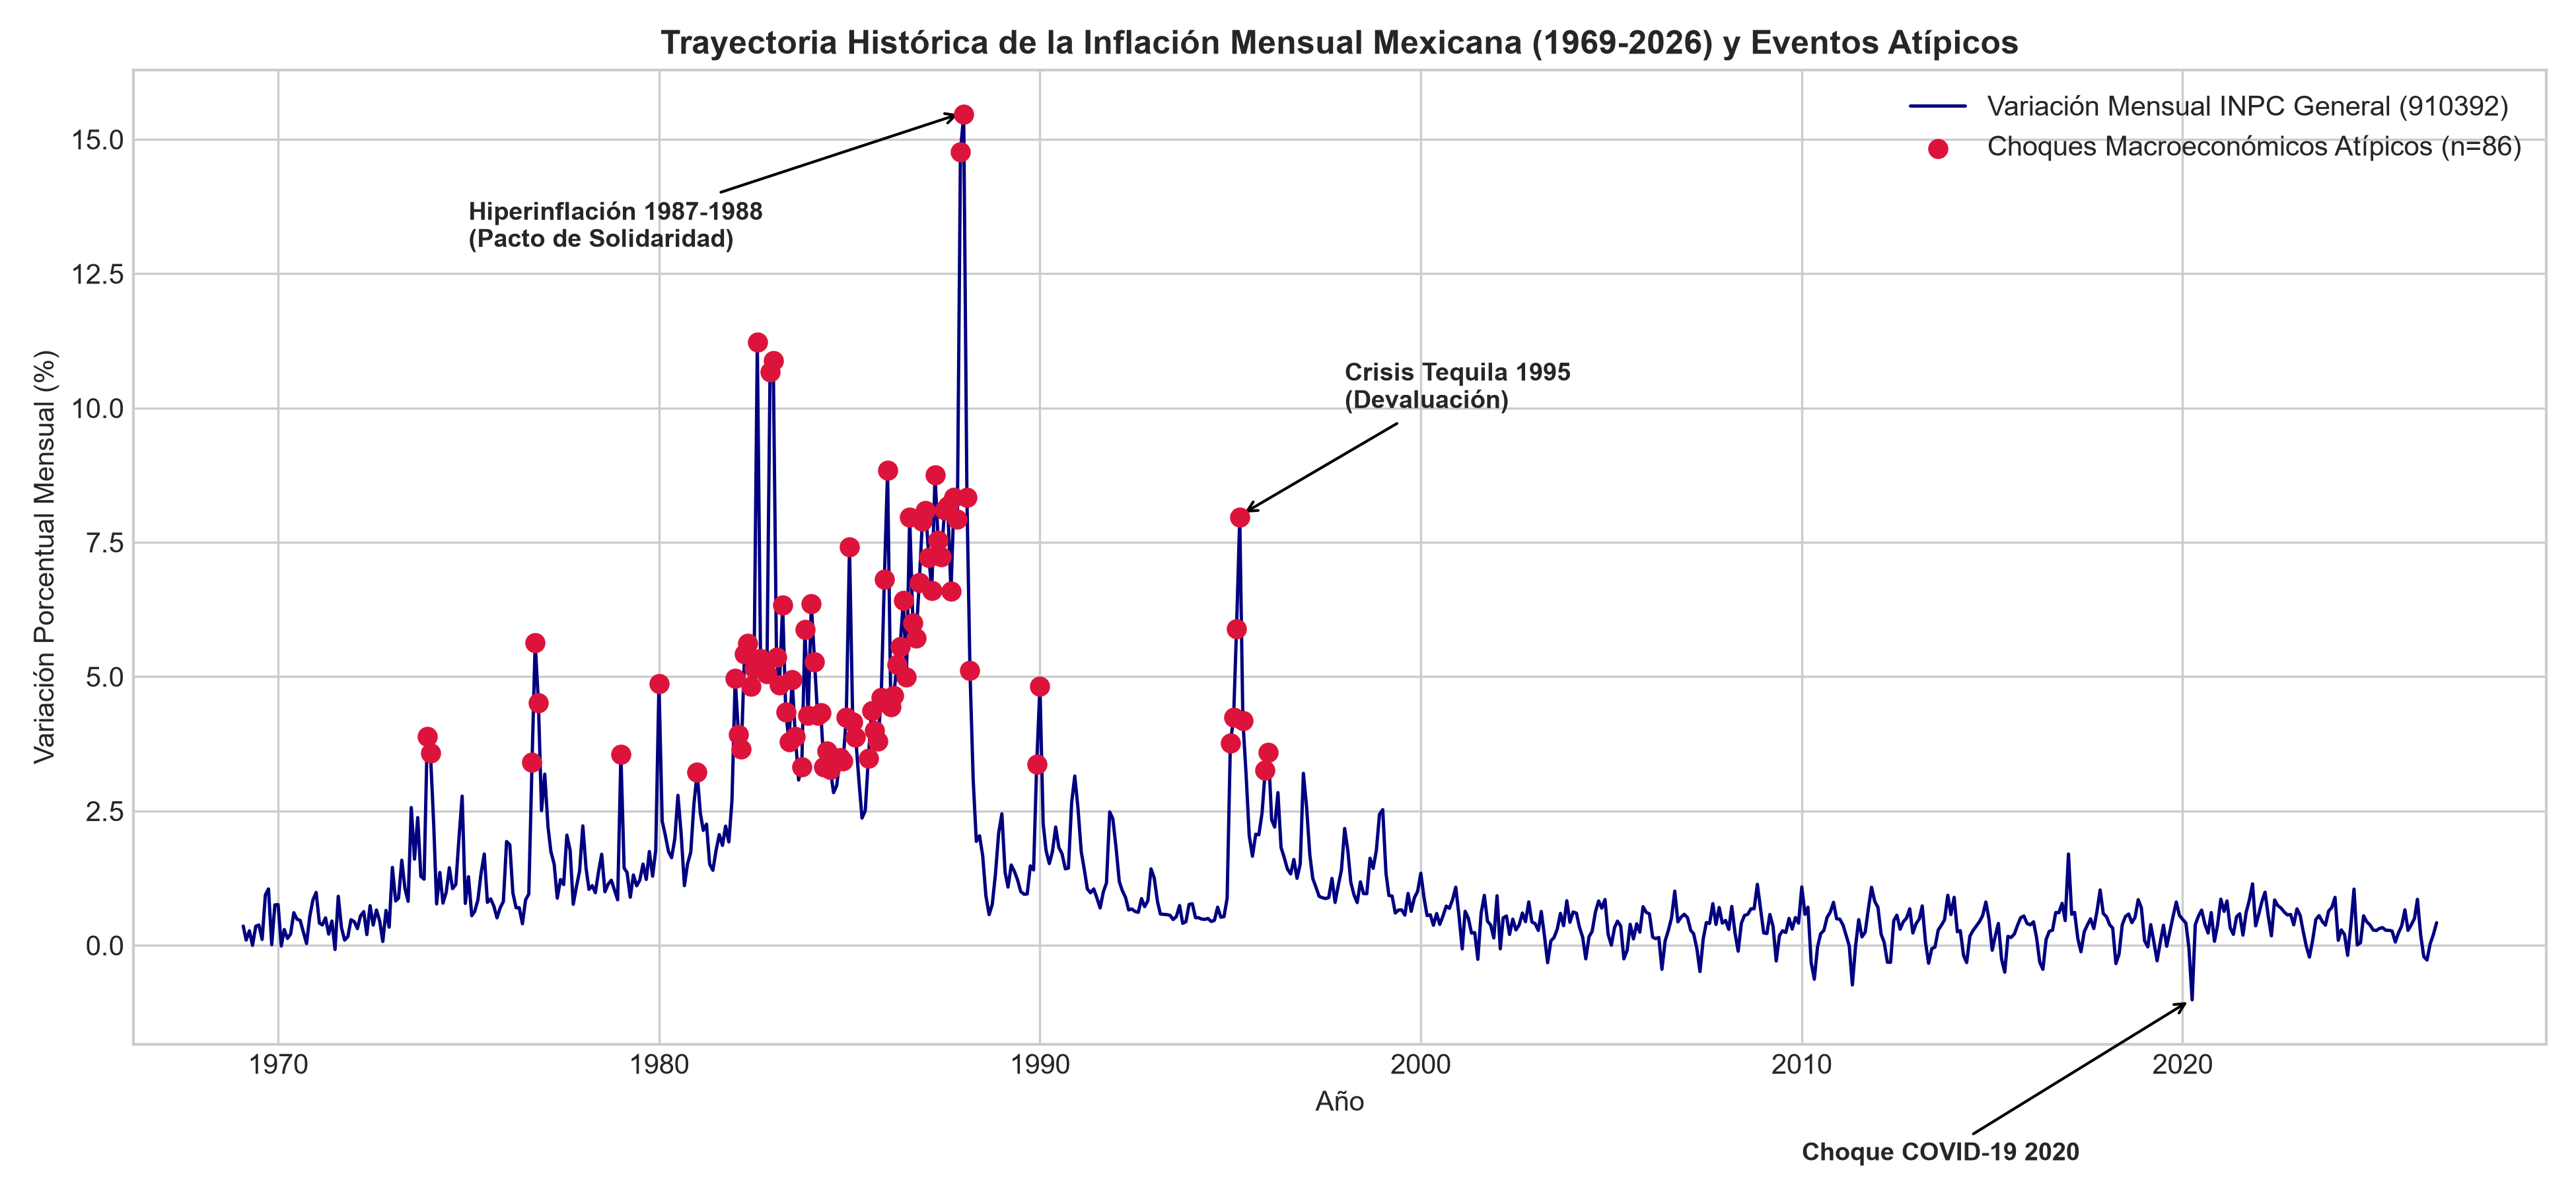

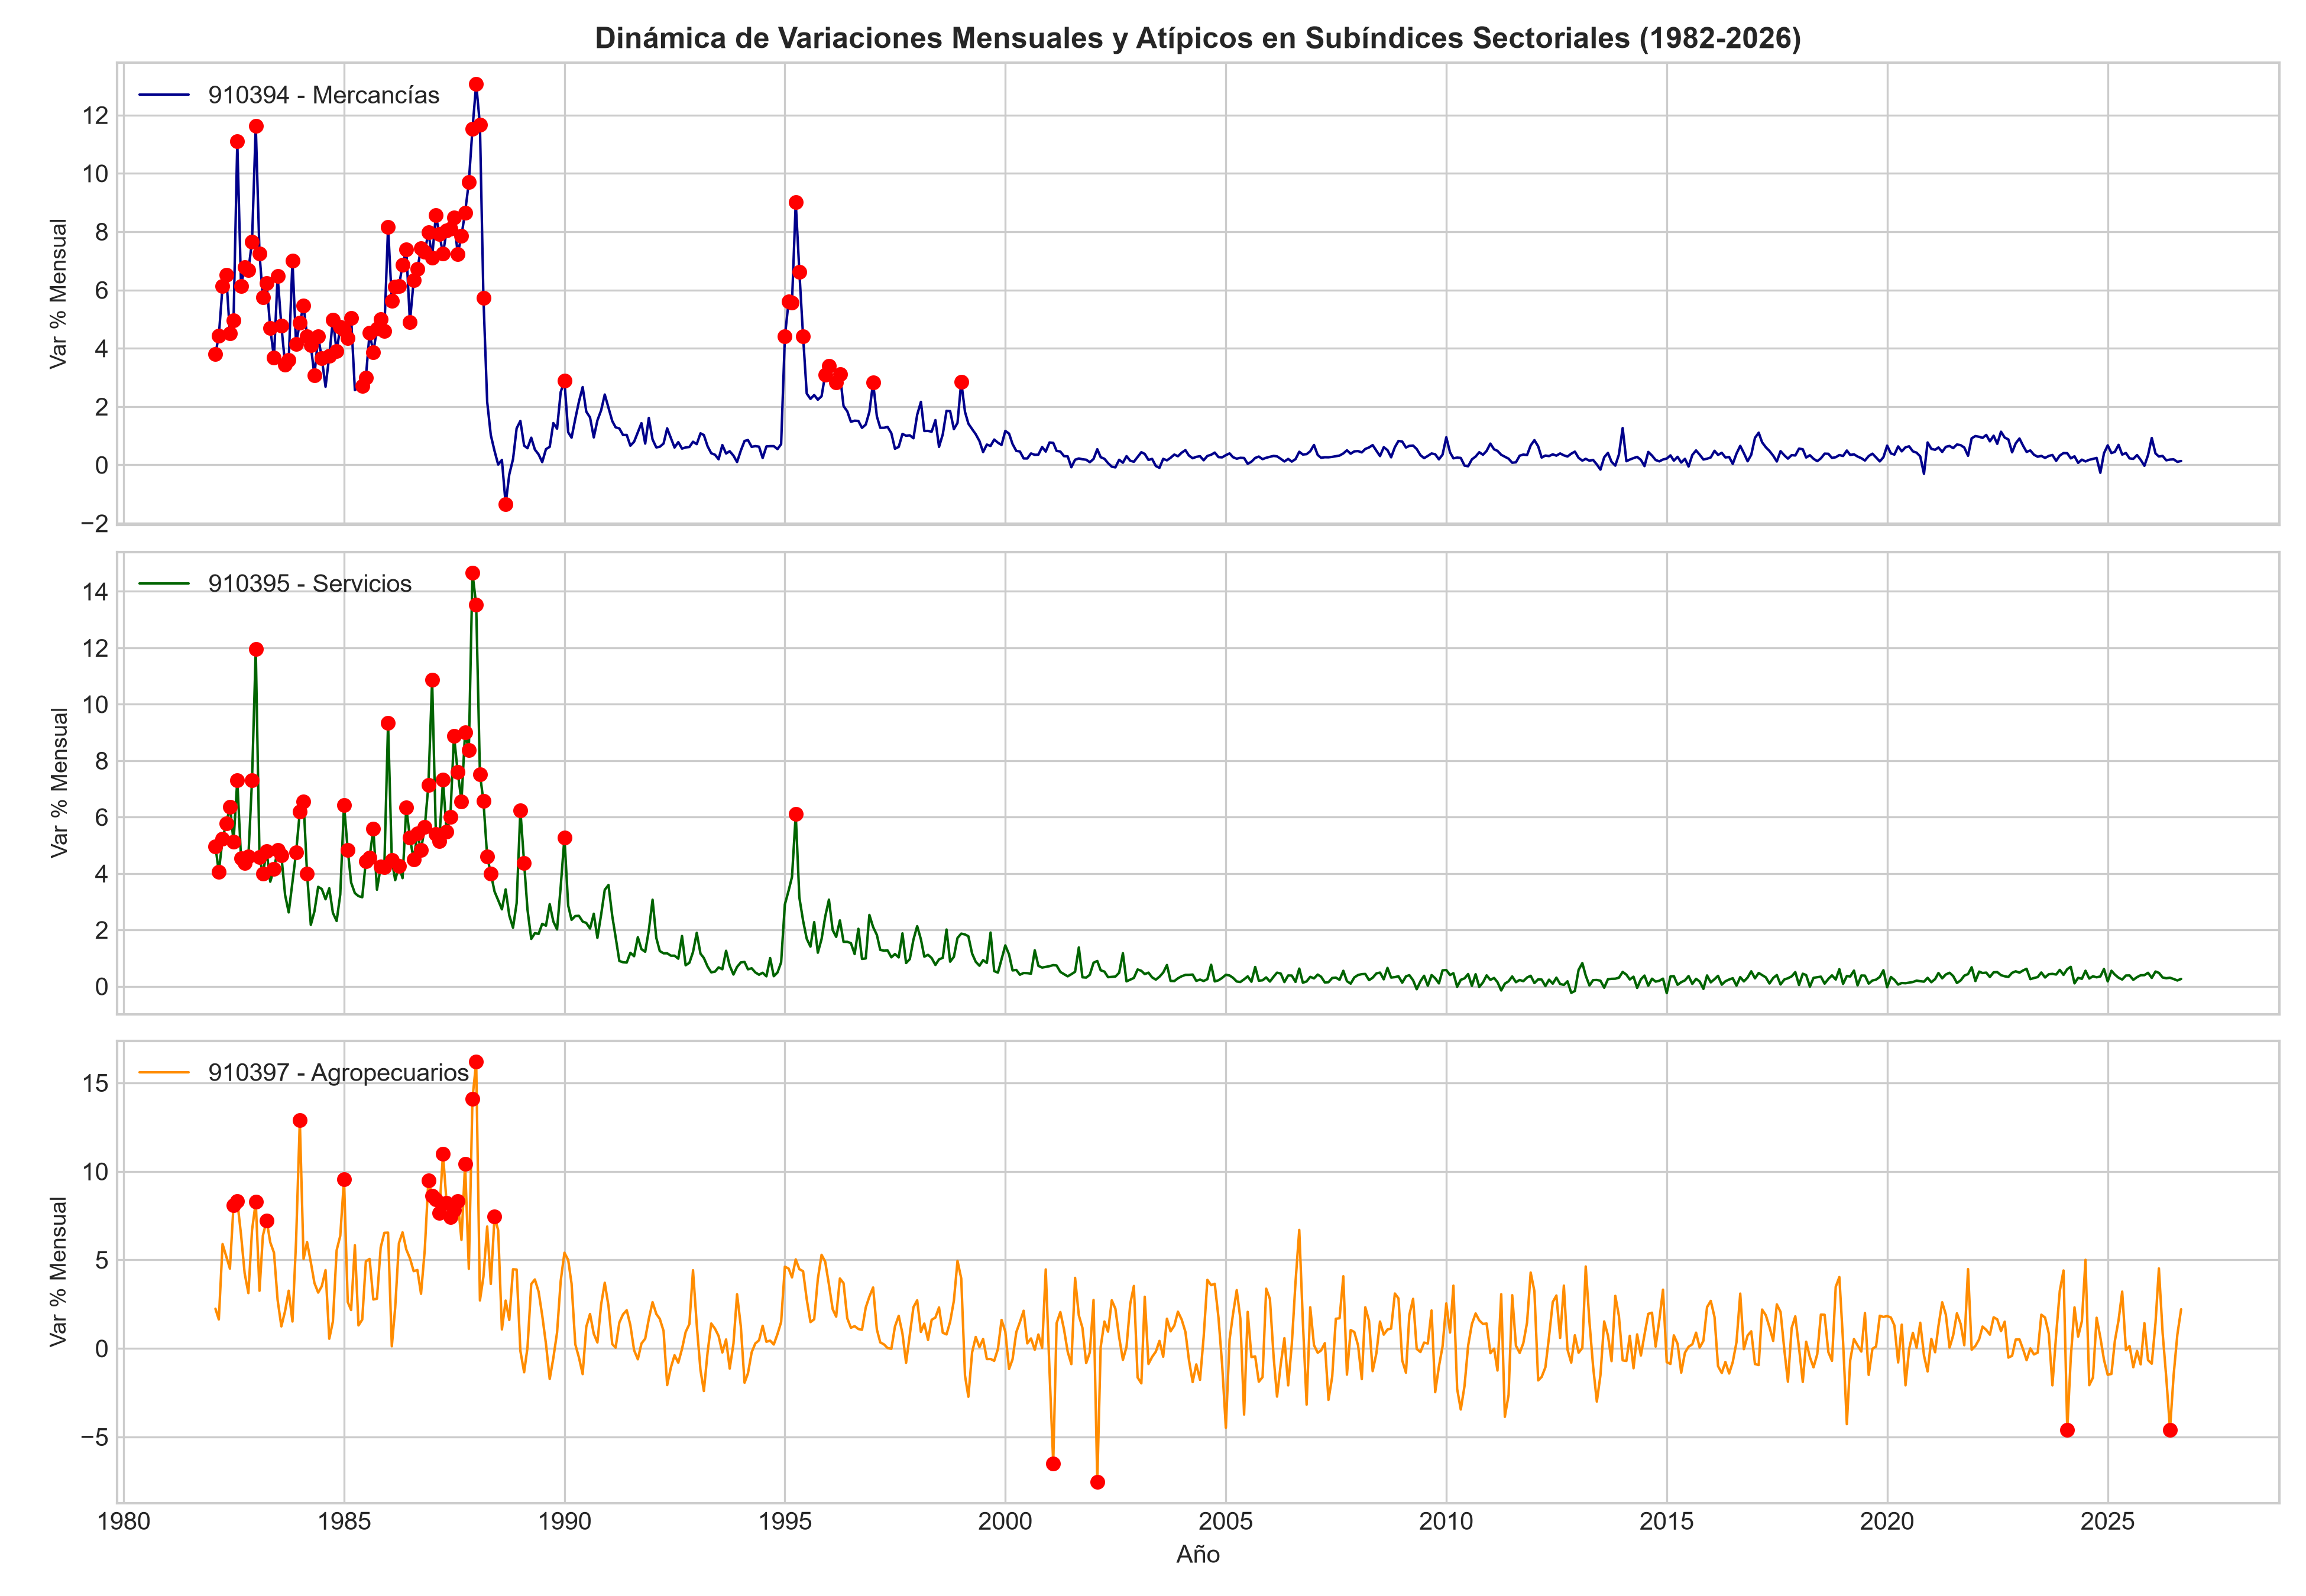

In [4]:
df_plata_limpio, resumen_atipicos = detectar_atipicos(df_plata_raw)

print("RESUMEN DE ATÍPICOS DETECTADOS POR MÉTODO:")
for cve, at in resumen_atipicos.items():
    print(f"[{cve}] {at['nombre']:30} | IQR: {at['iqr_conteo']:2} | ZMAD: {at['zmad_conteo']:2} | IForest: {at['iforest_conteo']:2}")

display.display(display.Image(filename=str(BASE_DIR / "docs" / "E1" / "figuras" / "boxplot_variaciones.png")))
display.display(display.Image(filename=str(BASE_DIR / "docs" / "E1" / "figuras" / "serie_atipicos_inpc.png")))
display.display(display.Image(filename=str(BASE_DIR / "docs" / "E1" / "figuras" / "serie_atipicos_mercancias_servicios.png")))


---
## Fase 4: Normalización, Discretización y Jerarquías Conceptuales

### 1. Normalización Reversible:
Se calcula la normalización Min-Max $[0, 1]$ y Z-score $(\mu=0, \sigma=1)$ para cada serie. Los parámetros $(\min, \max, \mu, \sigma)$ se persisten en `datos/plata/parametros_escalamiento.json` para permitir la desnormalización exacta de futuros pronósticos.

### 2. Jerarquías Conceptuales:
- **Temporal:** `año`, `semestre` (S1/S2), `trimestre` (T1-T4), `mes`, `nombre_mes`.
- **Ciclo Escolar / Vacaciones:**  
  `[SUPUESTO DEL DOMINIO: Basado en entrevista cualitativa de campo, no verificado administrativamente con calendarios SEP históricos de 1969-2026]`:
  - `Clases_Regulares`: Enero-Marzo, Mayo-Junio, Septiembre-Noviembre.
  - `Vacaciones_Verano`: Julio-Agosto.
  - `Vacaciones_Invierno`: Diciembre.
  - `Vacaciones_Semana_Santa`: Abril.
- **Inflación por Dominio Económico:**
  - `Deflación (<0%)`
  - `Moderada (0% a 0.4%)` (Meta Banxico ~3-5% anual)
  - `Alta (0.4% a 1.0%)`
  - `Severa (>1.0%)`

### 3. Reducción y Multicolinealidad (VIF):
Se calcula el Factor de Inflación de la Varianza (VIF) entre los subíndices de la canasta. No se aplica submuestreo porque la serie consta de 537 observaciones mensuales, volumen óptimo para modelado temporal sin pérdida de autocorrelación.


In [5]:
df_plata_final, parametros_norm, df_vif = transformar_y_normalizar(
    df_plata_limpio,
    parametros_path=BASE_DIR / "datos" / "plata" / "parametros_escalamiento.json"
)

print("MULTICOLINEALIDAD (VIF) ENTRE SUBÍNDICES (1982-2026):")
display.display(df_vif)

print("DISTRIBUCIÓN POR SUPUESTO DE CICLO ESCOLAR:")
display.display(df_plata_final.groupby("supuesto_ciclo_escolar")["valor"].count().to_frame("conteo_observaciones"))


2026-11-12 10:27:03,260 [INFO] Iniciando transformaciones, normalización y jerarquías conceptuales...


2026-11-12 10:27:03,284 [INFO] Parámetros de normalización guardados en: C:\Users\molin\Documents\7 SEMESTRE\ING Datos\Programas ING DATOS\Trusted Data Lab\datos\plata\parametros_escalamiento.json


2026-11-12 10:27:03,410 [INFO] Calculando matriz de correlación y VIF para reducción de variables...


MULTICOLINEALIDAD (VIF) ENTRE SUBÍNDICES (1982-2026):


,variable,vif,diagnostico_multicolinealidad
0,mercancias,5.738315,Alta (>5.0)
1,servicios,6.183977,Alta (>5.0)
2,agropecuarios,1.991879,Baja (<5.0)


DISTRIBUCIÓN POR SUPUESTO DE CICLO ESCOLAR:


,conteo_observaciones
supuesto_ciclo_escolar,
Clases_Regulares,7722
Vacaciones_Invierno,952
Vacaciones_Semana_Santa,936
Vacaciones_Verano,2025


---
## Fase 5: Puerta de Calidad Automática con Pandera

Se valida la tabla resultante con `pandera.DataFrameSchema` usando **evaluación perezosa** (`lazy=True`) para capturar cualquier inconformidad de tipos, rangos plausibles ($> 0$ y $< 1000$) y duplicados de clave temporal.

### Conciliación Contable Estricta:
$$\text{Total Entrada Cruda} = \text{Registros en Plata} + \text{Registros en Cuarentena}$$
Si la ecuación presenta una sola discrepancia, el pipeline detiene su ejecución.


In [6]:
puerta = PuertaCalidad(
    cuarentena_dir=BASE_DIR / "datos" / "cuarentena",
    reporte_path=BASE_DIR / "docs" / "E1" / "reporte_calidad.md"
)

df_validos, df_cuar_p = puerta.validar_y_segregar(df_plata_final)
df_cuarentena_total = pd.concat([df_cuarentena_f1, df_cuar_p], ignore_index=True)

total_entrada = len(df_plata_raw) + len(df_cuarentena_f1)
puerta.conciliar(total_entrada, df_validos, df_cuarentena_total)

print("Conciliación Verificada:")
print(f"  Entrada Cruda: {total_entrada:,}")
print(f"  Plata Válida:  {len(df_validos):,}")
print(f"  Cuarentena:    {len(df_cuarentena_total):,}")
print(f"  Discrepancia:  {total_entrada - (len(df_validos) + len(df_cuarentena_total))}")


2026-11-12 10:27:03,600 [INFO] Puerta de Calidad superada: 100% de los registros (11635) conformes.


2026-11-12 10:27:03,671 [INFO] CONCILIACIÓN VERIFICADA: 69249 (Entrada) == 11635 (Plata) + 57614 (Cuarentena).


Conciliación Verificada:
  Entrada Cruda: 69,249
  Plata Válida:  11,635
  Cuarentena:    57,614
  Discrepancia:  0


---
## Fase 6: Capa Oro y Diccionario de Datos

Se construyen en `datos/oro/` dos datasets especializados listos para análisis univariado y multivariado, sin aplicar aún modelos de pronóstico:
1. `matriz_mensual_macro`: Tabla ancha que combina las 5 series mensuales y el tipo de cambio FIX mensualizado con rezagos (lags a 1 y 3 meses), normalización Z-score y variables de calendario.
2. `comparativa_sectores`: Tabla estructurada para contrastar las dinámicas de Mercancías, Servicios y Agropecuarios.


In [7]:
matriz_macro, comparativa_sectores, df_verif_series = construir_capa_oro(
    df_plata_long=df_plata_final,
    df_tc_mensual=df_tc_mensual,
    oro_dir=BASE_DIR / "datos" / "oro",
    diccionario_path=BASE_DIR / "docs" / "E1" / "diccionario_datos.md"
)

print("VERIFICACIÓN DE PERIODOS POR SERIE (CUMPLIMIENTO >= 36):")
display.display(df_verif_series)

print(f"Matriz Mensual Macro (Oro): {matriz_macro.shape}")
print(f"Comparativa Sectores (Oro): {comparativa_sectores.shape}")
matriz_macro.head()


2026-11-12 10:27:03,689 [INFO] Iniciando construcción de datasets analíticos de Capa Oro...


2026-11-12 10:27:03,949 [INFO] Diccionario de datos generado en: C:\Users\molin\Documents\7 SEMESTRE\ING Datos\Programas ING DATOS\Trusted Data Lab\docs\E1\diccionario_datos.md


2026-11-12 10:27:03,951 [INFO] Datasets de Capa Oro construidos exitosamente:


2026-11-12 10:27:03,952 [INFO]   - matriz_mensual_macro: 537 filas x 31 columnas


2026-11-12 10:27:03,953 [INFO]   - comparativa_sectores: 1611 filas x 11 columnas


VERIFICACIÓN DE PERIODOS POR SERIE (CUMPLIMIENTO >= 36):


,cve_serie,nombre_literal,frecuencia,periodos,cumple_minimo_36,primera_fecha,ultima_fecha,meses_faltantes
0,910392,Índice general,Mensual,693,SÍ,1969-01-01,2026-09-01,0
1,910394,Mercancías,Mensual,537,SÍ,1982-01-01,2026-09-01,0
2,910395,Servicios,Mensual,537,SÍ,1982-01-01,2026-09-01,0
3,910397,Agropecuarios,Mensual,537,SÍ,1982-01-01,2026-09-01,0
4,SP74625,Subíndice subyacente del INPC,Mensual,537,SÍ,1982-01-01,2026-09-01,0
5,SF43718,Tipo de cambio FIX (Diario),Diaria hábil,8794,SÍ,1991-11-12,2026-11-06,0


Matriz Mensual Macro (Oro): (537, 31)
Comparativa Sectores (Oro): (1611, 11)


,fecha,inpc_general,inpc_mercancias,inpc_servicios,inpc_agropecuarios,inpc_subyacente_banxico,var_pct_general,var_pct_mercancias,var_pct_servicios,var_pct_agropecuarios,...,tipo_cambio_fix_cierre,var_pct_tc_promedio,lag1_var_tc_promedio,z_tc_promedio,año,mes,trimestre,semestre,es_temporada_calor,supuesto_ciclo_escolar
0,1982-01-01,0.085866,0.093648,0.088811,0.091769,0.092901,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1982,1,T1,S1,0,Clases_Regulares
1,1982-02-01,0.089240,0.097214,0.093212,0.093826,0.096869,3.929537,3.807994,4.955683,2.240652,...,NaN,NaN,NaN,NaN,1982,2,T1,S1,0,Clases_Regulares
2,1982-03-01,0.092499,0.101520,0.096995,0.095361,0.101014,3.652296,4.429521,4.058654,1.636332,...,NaN,NaN,NaN,NaN,1982,3,T1,S1,0,Clases_Regulares
3,1982-04-01,0.097512,0.107740,0.102070,0.100982,0.106836,5.419622,6.126547,5.231972,5.894553,...,NaN,NaN,NaN,NaN,1982,4,T2,S1,1,Vacaciones_Semana_Santa
4,1982-05-01,0.102993,0.114753,0.107958,0.106239,0.113471,5.620808,6.509707,5.768749,5.206224,...,NaN,NaN,NaN,NaN,1982,5,T2,S1,1,Clases_Regulares


---
## Conclusiones y Trazabilidad para la Entrega E1

1. **Integración Completa:** Se leyeron 69,249 registros crudos. Con 57,614 registros aislados en cuarentena (duplicados de capturas repetidas, series legadas 628xxx, Banxico SP1 y valores N/E pre-1982) y 11,635 observaciones válidas en Plata, la conciliación matemática es **100% exacta (discrepancia 0)**.
2. **Diagnóstico Factual de Faltantes:** Se demostró honestamente que las series activas vigentes tienen **0 meses faltantes**. El experimento de simulación demostró que la interpolación lineal es el método óptimo para este tipo de series integradas continuas.
3. **Preservación de Choques Reales:** No se eliminaron observaciones atípicas; los picos inflacionarios de 1987-1988 y 1995 corresponden a eventos macroeconómicos históricos de México que deben modelarse, no censurarse.
4. **Capa Oro Lista:** Se construyeron datasets limpios, enriquecidos con rezagos y variables estacionales, listos para la fase de modelado analítico.
